# TP3 — Multiple Linear Regression

## Learning goals

- Build a multiple-regression design matrix manually.
- Understand why the bias term is represented by a column of ones.
- Track gradient-descent convergence through the cost history.
- Compare a from-scratch model with scikit-learn's reference implementation.

The learned parameter vector contains one coefficient for each advertising
channel and one intercept. The final comparison should show close MSE and $R^2$
values when gradient descent has converged.

## Mathematical foundations

For a linear model, the prediction is the weighted sum of the input features:

$$
\hat{y} = X\theta
$$

The notebooks add a column of ones to $X$ when the intercept is learned as one
of the parameters in $\theta$. The objective is the half mean-squared error:

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})^2
$$

Its gradient is:

$$
\nabla_\theta J(\theta) = \frac{1}{m}X^T(X\theta-y)
$$

Gradient descent repeatedly updates the parameters in the direction that
reduces the cost:

$$
\theta \leftarrow \theta - \alpha\nabla_\theta J(\theta)
$$

where $m$ is the number of observations and $\alpha$ is the learning rate.
Model quality is reported with mean squared error and the coefficient of
determination:

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2,
\qquad
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$


# **TP3 Regression multiple**


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
%matplotlib inline

In [6]:
dataset=pd.read_csv("data/Advertising.csv")

In [7]:
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


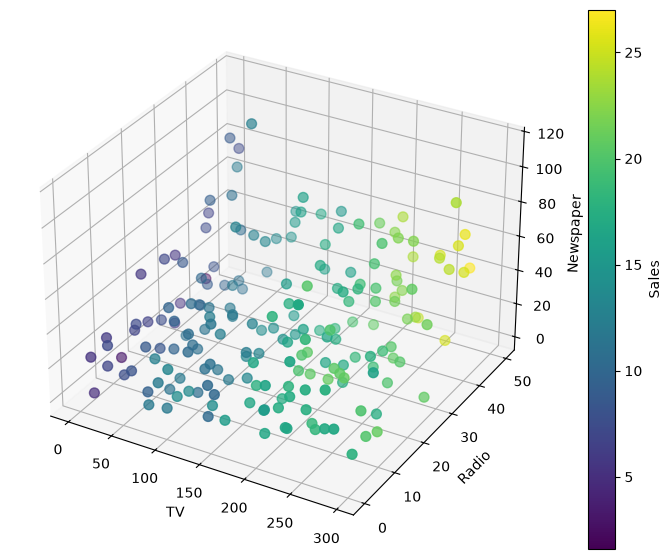

In [8]:
from mpl_toolkits.mplot3d import Axes3D

X1 = dataset["TV"]
X2 = dataset["Radio"]
X3 = dataset["Newspaper"]
Y  = dataset["Sales"]

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(X1, X2, X3, c=Y, cmap="viridis", s=50)

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")

plt.show()



In [9]:
X1.shape


(200,)

In [10]:
X2.shape

(200,)

In [11]:
X3.shape

(200,)

In [12]:
Y.shape

(200,)

In [13]:
Y = dataset["Sales"].values.reshape(-1, 1)

In [14]:
Y.shape

(200, 1)

In [15]:
X = np.column_stack((X1, X2, X3))
print(X.shape)


(200, 3)


In [16]:
X = np.hstack((X, np.ones((X.shape[0], 1))))
print(X.shape)

(200, 4)


In [17]:
print(X1)
print(X2)
print(X3)

0      230.1
1       44.5
2       17.2
3      151.5
4      180.8
       ...  
195     38.2
196     94.2
197    177.0
198    283.6
199    232.1
Name: TV, Length: 200, dtype: float64
0      37.8
1      39.3
2      45.9
3      41.3
4      10.8
       ... 
195     3.7
196     4.9
197     9.3
198    42.0
199     8.6
Name: Radio, Length: 200, dtype: float64
0      69.2
1      45.1
2      69.3
3      58.5
4      58.4
       ... 
195    13.8
196     8.1
197     6.4
198    66.2
199     8.7
Name: Newspaper, Length: 200, dtype: float64


In [18]:
print(X[:5])

[[230.1  37.8  69.2   1. ]
 [ 44.5  39.3  45.1   1. ]
 [ 17.2  45.9  69.3   1. ]
 [151.5  41.3  58.5   1. ]
 [180.8  10.8  58.4   1. ]]


In [19]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(160, 4)
(40, 4)
(160, 1)
(40, 1)


**2- ModÃ¨le**


In [20]:
np.random.seed(1)
theta_initial = np.random.randn(X_train.shape[1] , 1)
theta_initial

array([[ 1.62434536],
       [-0.61175641],
       [-0.52817175],
       [-1.07296862]])

In [21]:
def model(X, theta):
    return X.dot(theta)

**3- Fonction cout**


In [22]:
def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X, theta) - y)**2)

In [23]:
cost_function(X_train, Y_train, theta_initial)

np.float64(28280.30046860725)

In [24]:
def grad(X, y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X, theta) - y)

In [25]:
def gradient_descent(X, y, theta, learning_rate, n_iterations):

    cost_history = np.zeros(n_iterations)

    for i in range(0, n_iterations):
        theta = theta - learning_rate * grad(X, y, theta)
        cost_history[i] = cost_function(X, y, theta)

    return theta, cost_history

**TRAINING**


In [ ]:
n_iterations = 1200 000
learning_rate = 0.00001

theta_final, cost_history = gradient_descent(X_train, Y_train, theta_initial, learning_rate, n_iterations)

In [27]:
predictions = model(X_test, theta_final)
print(theta_final[0])
print(theta_final[1])
print(theta_final[2])
print(theta_final[3])

[0.05758522]
[0.11181422]
[0.01208054]
[3.62041351]


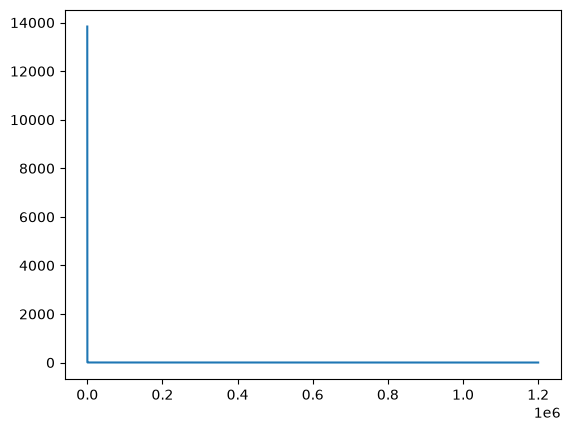

In [28]:
plt.plot(range(n_iterations), cost_history)
plt.show()

In [29]:
def coef_determination(y, pred):
    u = ((y - pred)**2).sum()
    v = ((y - y.mean())**2).sum()
    return 1 - u/v

In [30]:
coef_determination(Y_test, predictions)

np.float64(0.9024712113682267)

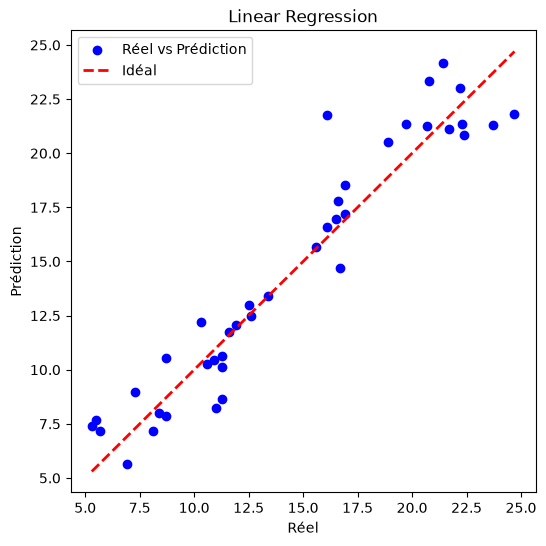

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(Y_test.ravel(), predictions.ravel(), color='blue', label='RÃ©el vs PrÃ©diction')

min_val = min(Y_test.min(), predictions.min())
max_val = max(Y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='IdÃ©al')

plt.title('Linear Regression')
plt.xlabel('RÃ©el')
plt.ylabel('PrÃ©diction')
plt.legend()
plt.show()


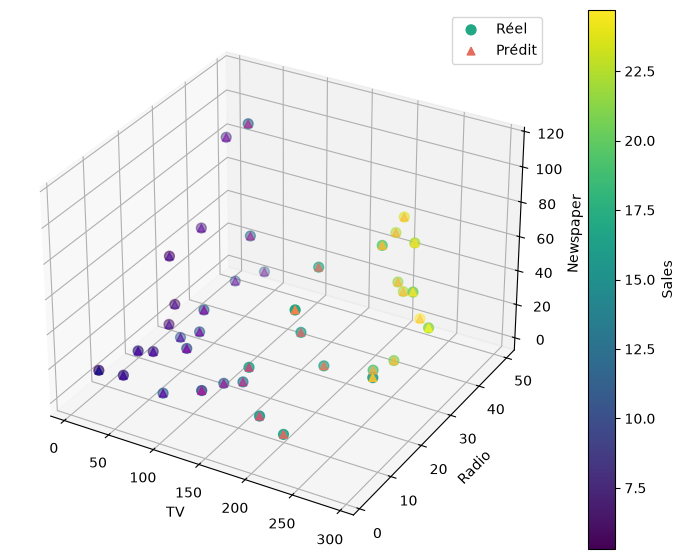

In [34]:
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')


sc = ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=Y_test, cmap="viridis", s=50, label="RÃ©el")

ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=predictions.ravel(), cmap="plasma", marker="^", s=30, label="PrÃ©dit")

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")
ax.legend()

plt.show()

In [35]:
coef_determination(Y_test, predictions)

np.float64(0.9024712113682267)

# EN UTILISANT SKLEARN


In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [38]:
sklearn_model = LinearRegression(fit_intercept=False)
sklearn_model.fit(X_train, y_train)
y_pred = sklearn_model.predict(X_test)

In [39]:
coef_determination(Y_test,  y_pred)

np.float64(0.9059011844150828)

In [41]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error mse:", mse)
print("RÂ² = ", r2)

Mean Squared Error mse: 2.907756910271085
RÂ² =  0.9059011844150828


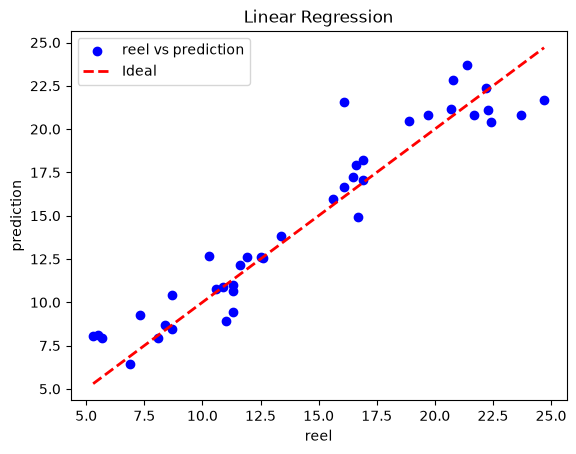

In [42]:
plt.scatter(y_test, y_pred, color='blue', label='reel vs prediction')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal ')

plt.title('Linear Regression')
plt.xlabel('reel')
plt.ylabel('prediction')
plt.legend()
plt.show()

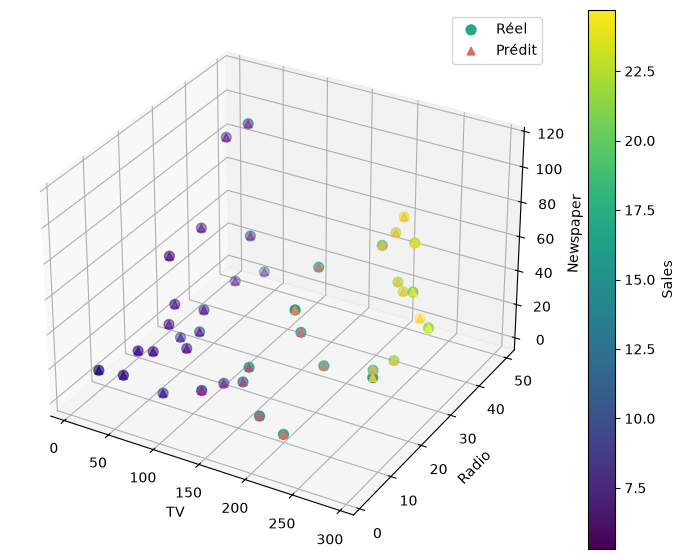

In [43]:
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')


sc = ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=Y_test, cmap="viridis", s=50, label="RÃ©el")

ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=y_pred, cmap="plasma", marker="^", s=30, label="PrÃ©dit")

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")
ax.legend()

plt.show()

In [45]:
from sklearn.metrics import mean_squared_error, r2_score
mse_scratch = mean_squared_error(Y_test,predictions)
r2_scratch = r2_score(Y_test,predictions)
mse_sklearn = mean_squared_error(y_test,y_pred)
r2_sklearn = r2_score(y_test,y_pred)
print("========== FROM SCRATCH ==========")
print("MSE :", mse_scratch)
print("RÂ²  :", r2_scratch)
print("\n========== SCIKIT-LEARN ==========")
print("MSE :", mse_sklearn)
print("RÂ²  :", r2_sklearn)
comparison = pd.DataFrame({"ModÃ¨le": ["From Scratch","Scikit-learn"],"MSE": [mse_scratch,mse_sklearn],"RÂ²": [r2_scratch,
        r2_sklearn
    ]
})
print("\n========== COMPARAISON ==========")
print(comparison)

========== FROM SCRATCH ==========
MSE : 3.0137468503892904
RÂ²  : 0.9024712113682267

========== SCIKIT-LEARN ==========
MSE : 2.907756910271085
RÂ²  : 0.9059011844150828

========== COMPARAISON ==========
         ModÃ¨le       MSE        RÂ²
0  From Scratch  3.013747  0.902471
1  Scikit-learn  2.907757  0.905901
